# What is in the wager file?

Each row represents an account's aggregated wagers on one hand. First check the observation period and the coverage of the fields needed to match rounds.

In [1]:
from pathlib import Path

import duckdb

database = Path("../private/wagers.duckdb")
con = duckdb.connect(str(database), read_only=True, config={"threads": 4, "memory_limit": "3GB"})

In [2]:
con.sql('''
    SELECT count(*) AS player_hands,
           count(DISTINCT member) AS accounts,
           count(DISTINCT game) AS games,
           count(DISTINCT date) AS observed_days,
           min(date) AS first_date, max(date) AS last_date
    FROM wagers
''').df()

,player_hands,accounts,games,observed_days,first_date,last_date
0,48443707,93817,11,101,2022-04-17,2022-07-26


## Fields needed for round matching

In [3]:
con.sql('''
    SELECT count(*) FILTER (
               WHERE tableNO IS NULL OR shoe_ref IS NULL OR shoe_hand IS NULL
           ) AS incomplete_hand_key,
           count(*) FILTER (WHERE min_time_stamp IS NULL) AS missing_timestamp,
           count(*) FILTER (WHERE bet IS NULL OR bet <= 0) AS nonpositive_or_missing_stake,
           count(*) FILTER (WHERE ip IS NULL OR ip = '') AS missing_ip
    FROM wagers
''').df()

,incomplete_hand_key,missing_timestamp,nonpositive_or_missing_stake,missing_ip
0,541,0,0,4747595


## Volume by game

I use player-hand records here because a single row can cover multiple bet slips. The coordination audit focuses on games where two opposing main bets have a clear meaning.

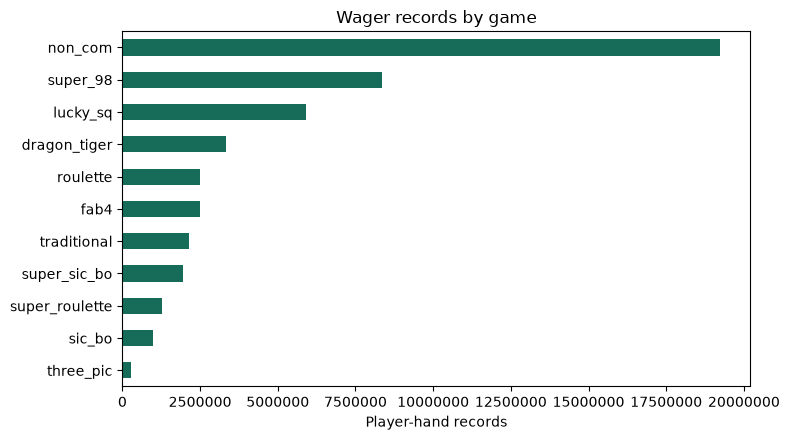

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

by_game = con.sql('''
    SELECT game, count(*) AS player_hands
    FROM wagers
    GROUP BY game
    ORDER BY player_hands
''').df()

ax = by_game.plot.barh(x="game", y="player_hands", legend=False, color="#176c59", figsize=(8, 4.5))
ax.set(xlabel="Player-hand records", ylabel="", title="Wager records by game")
ax.ticklabel_format(style="plain", axis="x")
ax.get_figure().tight_layout()
plt.show()
con.close()